# Supplementary Figure 1: ClinVar benchmark construction pipeline

This notebook generates the editable vector flow diagram used as Supplementary Figure 1.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

FIGURE_DIR = Path('results/figures')
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'svg.fonttype': 'none', 'pdf.fonttype': 42, 'ps.fonttype': 42, 'font.family': 'Arial'})


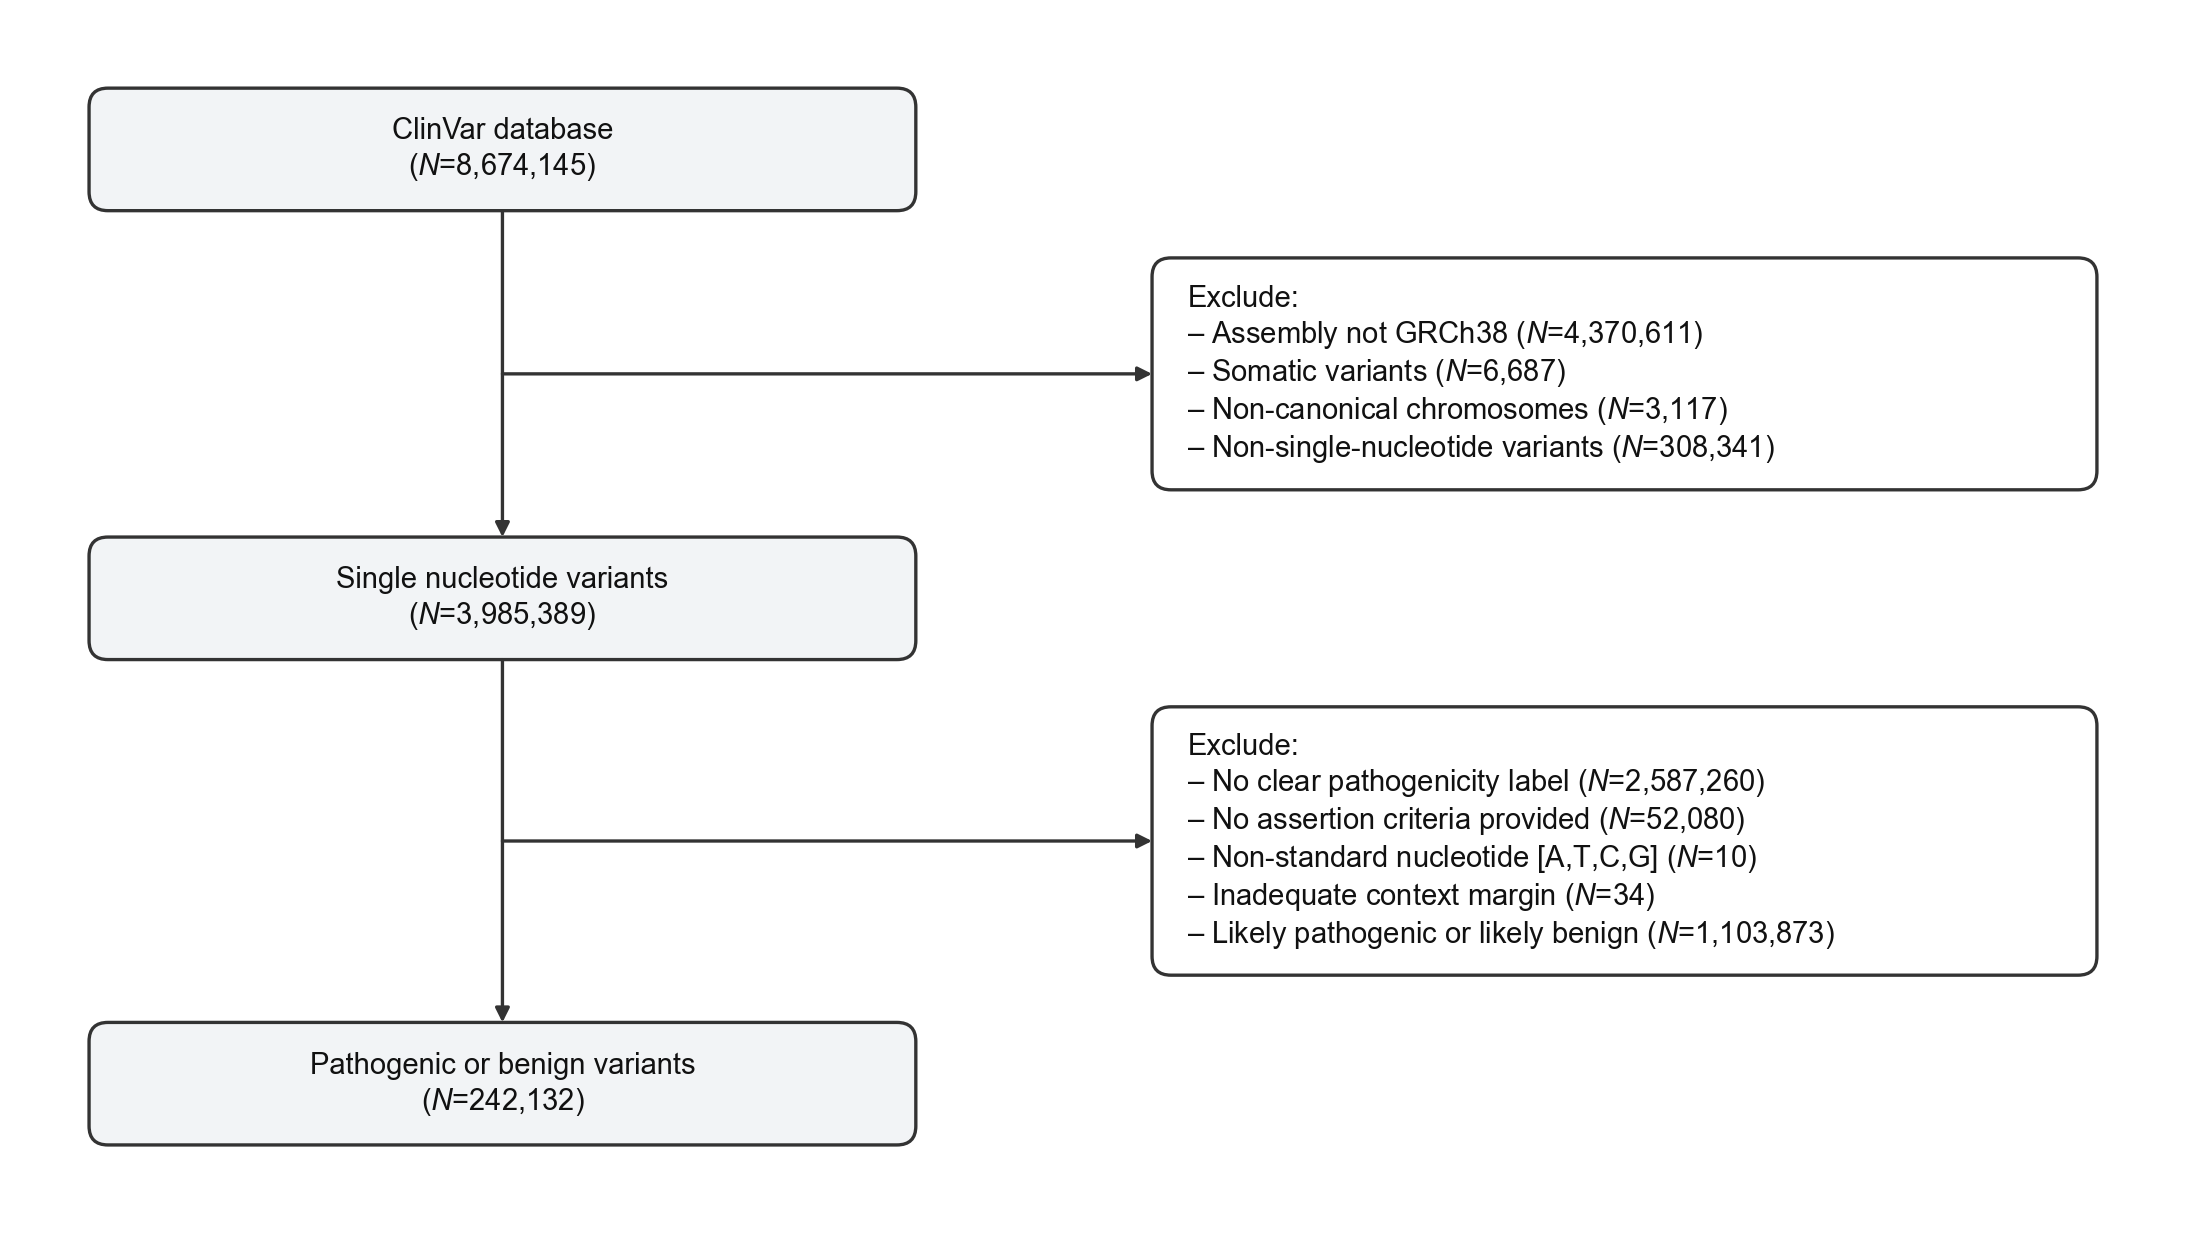

In [2]:
plt.rcParams.update({"mathtext.fontset": "custom", "mathtext.rm": "Arial",
                     "mathtext.it": "Arial:italic", "mathtext.bf": "Arial:bold"})
# Supplementary Figure 1 is laid out directly in millimetres so that every edge, branch and
# arrowhead is derived from the content rather than hand-tuned. Box heights follow their own
# line count, each exclusion callout is centred on the branch that feeds it, and each branch
# leaves the spine at the midpoint of the gap so it never collides with the arrowhead below.
FIG_W_MM = 180.0

MARGIN = 5.0
SPINE_X, SPINE_W = 5.0, 70.0          # main pipeline column
CALLOUT_X, CALLOUT_W = 95.0, 80.0     # exclusion column
SPINE_CX = SPINE_X + SPINE_W / 2.0    # vertical arrow runs down this line

MAIN_FS, CALLOUT_FS = 7.0, 7.0   # 7 pt is the journal maximum
LINE_SPACING = 1.25
PT_MM = 25.4 / 72.0
BOX_PAD_Y = 4.2                       # vertical breathing room inside a box
GAP_CLEAR = 4.0                       # clearance between a callout and the boxes above/below

EDGE, FILL_MAIN, FILL_CALLOUT = "#333333", "#F2F4F6", "white"

STEPS = [
    "ClinVar database\n($N$=8,674,145)",
    "Single nucleotide variants\n($N$=3,985,389)",
    "Pathogenic or benign variants\n($N$=242,132)",
]
EXCLUSIONS = [
    "Exclude:\n"
    "\u2013 Assembly not GRCh38 ($N$=4,370,611)\n"
    "\u2013 Somatic variants ($N$=6,687)\n"
    "\u2013 Non-canonical chromosomes ($N$=3,117)\n"
    "\u2013 Non-single-nucleotide variants ($N$=308,341)",
    "Exclude:\n"
    "\u2013 No clear pathogenicity label ($N$=2,587,260)\n"
    "\u2013 No assertion criteria provided ($N$=52,080)\n"
    "\u2013 Non-standard nucleotide [A,T,C,G] ($N$=10)\n"
    "\u2013 Inadequate context margin ($N$=34)\n"
    "\u2013 Likely pathogenic or likely benign ($N$=1,103,873)",
]


def block_height(text, fontsize):
    """Height in millimetres of a text block, from its line count."""
    lines = text.count("\n") + 1
    return lines * fontsize * LINE_SPACING * PT_MM + BOX_PAD_Y


step_h = [block_height(t, MAIN_FS) for t in STEPS]
callout_h = [block_height(t, CALLOUT_FS) for t in EXCLUSIONS]
# Each gap must host its callout plus clearance above and below.
gap_h = [h + 2 * GAP_CLEAR for h in callout_h]

fig_h_mm = MARGIN * 2 + sum(step_h) + sum(gap_h)
fig, axis = plt.subplots(figsize=(FIG_W_MM / 25.4, fig_h_mm / 25.4), dpi=300)
axis.set_xlim(0, FIG_W_MM)
axis.set_ylim(0, fig_h_mm)
axis.set_aspect("equal")
axis.axis("off")

# Walk down the page, recording where each box sits.
step_top, step_bottom, cursor = [], [], fig_h_mm - MARGIN
for i, h in enumerate(step_h):
    step_top.append(cursor)
    cursor -= h
    step_bottom.append(cursor)
    if i < len(gap_h):
        cursor -= gap_h[i]


def rounded_box(x, y, w, h, facecolor):
    axis.add_patch(FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0,rounding_size=1.6",
        linewidth=0.8, edgecolor=EDGE, facecolor=facecolor, mutation_aspect=1))


for text, top, bottom in zip(STEPS, step_top, step_bottom):
    rounded_box(SPINE_X, bottom, SPINE_W, top - bottom, FILL_MAIN)
    axis.text(SPINE_CX, (top + bottom) / 2, text, ha="center", va="center",
              fontsize=MAIN_FS, linespacing=LINE_SPACING, color="#111111")

for i, (text, height) in enumerate(zip(EXCLUSIONS, callout_h)):
    gap_top, gap_bottom = step_bottom[i], step_top[i + 1]
    branch_y = (gap_top + gap_bottom) / 2.0

    # Spine arrow: full length of the gap, arrowhead landing on the next box.
    axis.add_patch(FancyArrowPatch(
        (SPINE_CX, gap_top), (SPINE_CX, gap_bottom), arrowstyle="-|>",
        mutation_scale=7, linewidth=0.8, color=EDGE, shrinkA=0, shrinkB=0))

    # Branch: leaves the spine at the midpoint of the gap, well clear of the arrowhead,
    # and points into the callout, which is centred on the same line.
    rounded_box(CALLOUT_X, branch_y - height / 2, CALLOUT_W, height, FILL_CALLOUT)
    axis.add_patch(FancyArrowPatch(
        (SPINE_CX, branch_y), (CALLOUT_X, branch_y), arrowstyle="-|>",
        mutation_scale=7, linewidth=0.8, color=EDGE, shrinkA=0, shrinkB=0))
    axis.text(CALLOUT_X + 3.0, branch_y, text, ha="left", va="center",
              fontsize=CALLOUT_FS, linespacing=LINE_SPACING, color="#111111")

fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
for extension in ("svg", "pdf", "png"):
    fig.savefig(FIGURE_DIR / f"figure_s1.{extension}", dpi=300, facecolor="white")
plt.show()
